# 심화 06 · 배치 증강의 동작 구조와 원본 대비 검증

`main.py`의 H06 구현을 실행하고 train 이미지의 좌우반전·밝기 변화 및 원본 보존을 검증합니다.

필요 패키지: `opencv-python`, `numpy`, `pandas`, `matplotlib`, `IPython`. 프로젝트 내부에서 패키지가 설치된 커널로 위에서부터 실행하세요. 실행 시 `outputs/`의 증강 이미지와 CSV를 다시 생성합니다.

## 1. 동작 구조

1. manifest를 읽어 sample_id 순서로 정렬합니다.
2. split이 train인 이미지 4장만 처리합니다. valid/test는 건너뜁니다.
3. `seed = 42 + ID의 숫자 부분`으로 각 표본의 설정을 고정합니다.
4. 로컬 난수 생성기에서 좌우반전 여부와 밝기 beta(-20~20)를 뽑습니다.
5. 반전 또는 복사한 배열을 float32로 바꾼 뒤 beta를 더합니다.
6. `clip(0, 255)` 후 uint8로 변환하여 별도 PNG에 저장합니다.
7. 설정, 저장 성공 여부, 원본 파일 SHA-256을 CSV에 기록합니다.

float 변환은 uint8 덧셈의 순환을 피합니다. 예를 들어 250+13은 7로 순환하지 않고 clip을 거쳐 255가 됩니다. 하한·상한에서 잘린 값은 원래 밝기로 되돌릴 수 없습니다.

로컬 Generator는 같은 seed의 재현을 지원하며 전역 난수 시드를 재설정하지 않습니다. 같은 seed가 의미상 올바른 증강이나 라벨 보존까지 보장하는 것은 아닙니다.

In [1]:
from pathlib import Path
import os
import hashlib
import pandas as pd
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

notebook_start = Path.cwd().resolve()
project = next((p for p in [notebook_start, *notebook_start.parents]
                if (p / "20261104/03_심화/06_batch_augmentation/main.py").is_file()), None)
if project is None:
    raise FileNotFoundError("프로젝트 내부에서 실행하세요.")
exercise = project / "20261104/03_심화/06_batch_augmentation"
data_dir = exercise.parent / "data"
manifest = pd.read_csv(data_dir / "manifest.csv").sort_values("sample_id")
# 실행 전 파일 해시와 픽셀을 보관하여 실행 후 실제 원본 보존을 확인합니다.
before_hashes = {}
before_images = {}
for row in manifest.itertuples(index=False):
    path = data_dir / row.path
    before_hashes[row.sample_id] = hashlib.sha256(path.read_bytes()).hexdigest()
    image_before = cv2.imread(str(path))
    if image_before is None:
        raise RuntimeError(f"입력 읽기 실패: {row.sample_id}")
    before_images[row.sample_id] = image_before.copy()
display(manifest)

,sample_id,path,split,group_id,label,allow_flip
0,img_01,images/train_01.png,train,g01,geometric_shapes,1
1,img_02,images/train_02.png,train,g02,geometric_shapes,1
2,img_03,images/train_03.png,train,g03,geometric_shapes,1
3,img_04,images/train_04.png,train,g04,geometric_shapes,1
4,img_05,images/valid_05.png,valid,g05,geometric_shapes,1
5,img_06,images/test_06.png,test,g06,geometric_shapes,1


## 2. 현재 코드 실행

원본 코드의 경로 준비 부분에서 `__file__`만 노트북의 `exercise`로 바꿨습니다. `augment()`는 원본 배열을 덮어쓰지 않고 새로운 결과와 설정을 반환합니다. SHA-256 기록은 파일 식별을 돕는 값으로 보안 인증은 아닙니다.

In [2]:
from pathlib import Path
import os
import cv2
import numpy as np

# 제공 코드: 어느 작업 폴더에서 실행해도 현재 파일 옆의 입력을 읽습니다.
# OpenCV에는 영문 상대 경로를 전달합니다. 원본 파일은 덮어쓰지 않습니다.
os.chdir(exercise)

import csv
import json
from time import perf_counter
Path("outputs").mkdir(exist_ok=True)

import hashlib

def augment(image,seed):
    rng=np.random.default_rng(seed)
    flip=bool(rng.random()<0.5); beta=int(rng.integers(-20,21))
    result=cv2.flip(image,1) if flip else image.copy()
    # >>> TODO H06
    # beta를 적용하되 uint8의 순환을 막고 값 범위를 지키세요. 원본 image는 수정하지 않습니다.
    result=np.clip(result.astype(np.float32)+beta,0,255).astype(np.uint8)
    # <<< TODO H06
    return result,{"seed":seed,"flip":flip,"beta":beta}

with open("../data/manifest.csv",encoding="utf-8-sig",newline="") as f:
    sources=list(csv.DictReader(f))

rows=[]
for row in sorted(sources,key=lambda r:r["sample_id"]):
    if row["split"]!="train":
        continue  # valid/test는 증강 대상이 아닙니다.
    seed=42+int(row["sample_id"].split("_")[-1])
    src=Path("../data")/row["path"];image=cv2.imread(str(src))
    result,settings=augment(image,seed);dest=Path("outputs")/(row["sample_id"]+"_aug.png")
    saved=cv2.imwrite(str(dest),result)
    rows.append([row["sample_id"],row["split"],str(dest),seed,settings["flip"],settings["beta"],saved,hashlib.sha256(src.read_bytes()).hexdigest()])
with open("outputs/augmentation.csv","w",encoding="utf-8-sig",newline="") as f:
    w=csv.writer(f);w.writerow(["id","split","output","seed","flip","beta","saved","source_sha256"]);w.writerows(rows)
print("증강 이미지:",len(rows),"/ train만 처리")
print("설정:",[(r[0],r[3],r[4],r[5]) for r in rows])


증강 이미지: 4 / train만 처리
설정: [('img_01', 43, False, -4), ('img_02', 44, True, 13), ('img_03', 45, False, 9), ('img_04', 46, False, -12)]


## 3. 실제 설정과 픽셀 변화

기존 원본과 저장 PNG의 크기·자료형·범위를 비교합니다. **평균 절대차**는 반전도 포함한 최종 이미지와 원본의 같은 좌표를 비교한 값입니다. 밝기 변화량만을 나타내지는 않습니다.

**범위 초과 채널 값 수**는 반전 후 beta를 더한 값이 0 미만 또는 255 초과인 채널 원소 수입니다. 픽셀 수와 구분하며 경계와 같은 값은 포함하지 않습니다.

In [3]:
recorded = pd.read_csv("outputs/augmentation.csv")
assert not recorded["id"].duplicated().any()
assert set(recorded["id"]) == set(manifest.loc[manifest["split"] == "train", "sample_id"])
comparison_rows = []
verification_rows = []
processed_images = {}
for item in recorded.itertuples(index=False):
    original = before_images[item.id]
    snapshot = original.copy()
    output = cv2.imread(str(exercise / item.output))
    assert output is not None
    processed_images[item.id] = output
    seed = int(item.seed)
    flip = str(item.flip).lower() == "true"
    beta = int(item.beta)
    aligned = cv2.flip(original, 1) if flip else original.copy()
    raw = aligned.astype(np.float32) + beta
    expected = np.clip(raw, 0, 255).astype(np.uint8)
    run1, settings1 = augment(original, seed)
    run2, settings2 = augment(original, seed)
    source_row = manifest.loc[manifest["sample_id"] == item.id].iloc[0]
    current_hash = hashlib.sha256((data_dir / source_row["path"]).read_bytes()).hexdigest()
    comparison_rows.append({"ID": item.id, "seed": seed, "좌우반전": flip, "beta": beta,
                            "원본 크기 (W×H)": f"{original.shape[1]}×{original.shape[0]}",
                            "처리 크기 (W×H)": f"{output.shape[1]}×{output.shape[0]}",
                            "원본 범위": f"{original.min()}~{original.max()}",
                            "처리 범위": f"{output.min()}~{output.max()}",
                            "평균 절대차": round(float(np.abs(output.astype(np.float32) - original.astype(np.float32)).mean()), 4),
                            "범위 초과 채널 값 수": int(((raw < 0) | (raw > 255)).sum())})
    verification_rows.append({"ID": item.id,
                              "크기·dtype 유지": output.shape == original.shape and output.dtype == original.dtype == np.uint8,
                              "직접 계산과 저장 PNG 일치": np.array_equal(output, expected),
                              "같은 seed 재현": np.array_equal(run1, run2) and settings1 == settings2,
                              "CSV 설정 일치": settings1 == {"seed": seed, "flip": flip, "beta": beta},
                              "반환 결과·PNG 일치": np.array_equal(run1, output),
                              "원본 배열 보존": np.array_equal(original, snapshot),
                              "실행 전후 원본 해시 일치": current_hash == before_hashes[item.id],
                              "CSV 원본 해시 일치": item.source_sha256 == before_hashes[item.id],
                              "저장 성공 기록": str(item.saved).lower() == "true"})
comparison = pd.DataFrame(comparison_rows)
verification = pd.DataFrame(verification_rows)
display(comparison)
display(verification)
assert verification.drop(columns="ID").all().all()

,ID,seed,좌우반전,beta,원본 크기 (W×H),처리 크기 (W×H),원본 범위,처리 범위,평균 절대차,범위 초과 채널 값 수
0,img_01,43,False,-4,320×240,320×240,41~232,37~228,4.0000,0
1,img_02,44,True,13,320×240,320×240,22~236,35~249,19.3469,0
2,img_03,45,False,9,320×240,320×240,31~229,40~238,9.0000,0
3,img_04,46,False,-12,320×240,320×240,12~238,0~226,12.0000,0


,ID,크기·dtype 유지,직접 계산과 저장 PNG 일치,같은 seed 재현,CSV 설정 일치,반환 결과·PNG 일치,원본 배열 보존,실행 전후 원본 해시 일치,CSV 원본 해시 일치,저장 성공 기록
0,img_01,True,True,True,True,True,True,True,True,True
1,img_02,True,True,True,True,True,True,True,True,True
2,img_03,True,True,True,True,True,True,True,True,True
3,img_04,True,True,True,True,True,True,True,True,True


## 4. train·valid·test 전체 분할 검증

train에는 증강 결과가 있고 valid/test에는 해당 ID의 증강 파일이 없는지 확인합니다. 모든 입력 파일을 실행 전·후 해시와 픽셀로 비교합니다. 원본이 아닌 출력 파일을 따로 생성했는지 확인하는 과정입니다.

In [4]:
split_rows = []
for row in manifest.itertuples(index=False):
    source_path = data_dir / row.path
    output_path = exercise / "outputs" / f"{row.sample_id}_aug.png"
    current_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()
    unchanged = (current_hash == before_hashes[row.sample_id]
                 and np.array_equal(cv2.imread(str(source_path)), before_images[row.sample_id]))
    expected_output = row.split == "train"
    split_rows.append({"ID": row.sample_id, "split": row.split,
                       "증강 대상": expected_output, "증강 파일 존재": output_path.exists(),
                       "대상 처리 여부 일치": output_path.exists() == expected_output,
                       "원본 파일·픽셀 보존": unchanged})
split_verification = pd.DataFrame(split_rows)
display(split_verification)
assert split_verification["대상 처리 여부 일치"].all()
assert split_verification["원본 파일·픽셀 보존"].all()
assert len(recorded) == 4
print("검증 통과: train 4장 증강, valid/test 제외, 원본 보존 및 재현 일치")

,ID,split,증강 대상,증강 파일 존재,대상 처리 여부 일치,원본 파일·픽셀 보존
0,img_01,train,True,True,True,True
1,img_02,train,True,True,True,True
2,img_03,train,True,True,True,True
3,img_04,train,True,True,True,True
4,img_05,valid,False,False,True,True
5,img_06,test,False,False,True,True


검증 통과: train 4장 증강, valid/test 제외, 원본 보존 및 재현 일치


## 5. 원본과 처리 결과 나란히 보기

이미지 표시는 OpenCV의 BGR을 RGB로 변환합니다. 이 변환은 표시용이며 검증에 사용한 원본 배열과 PNG 파일을 변경하지 않습니다.

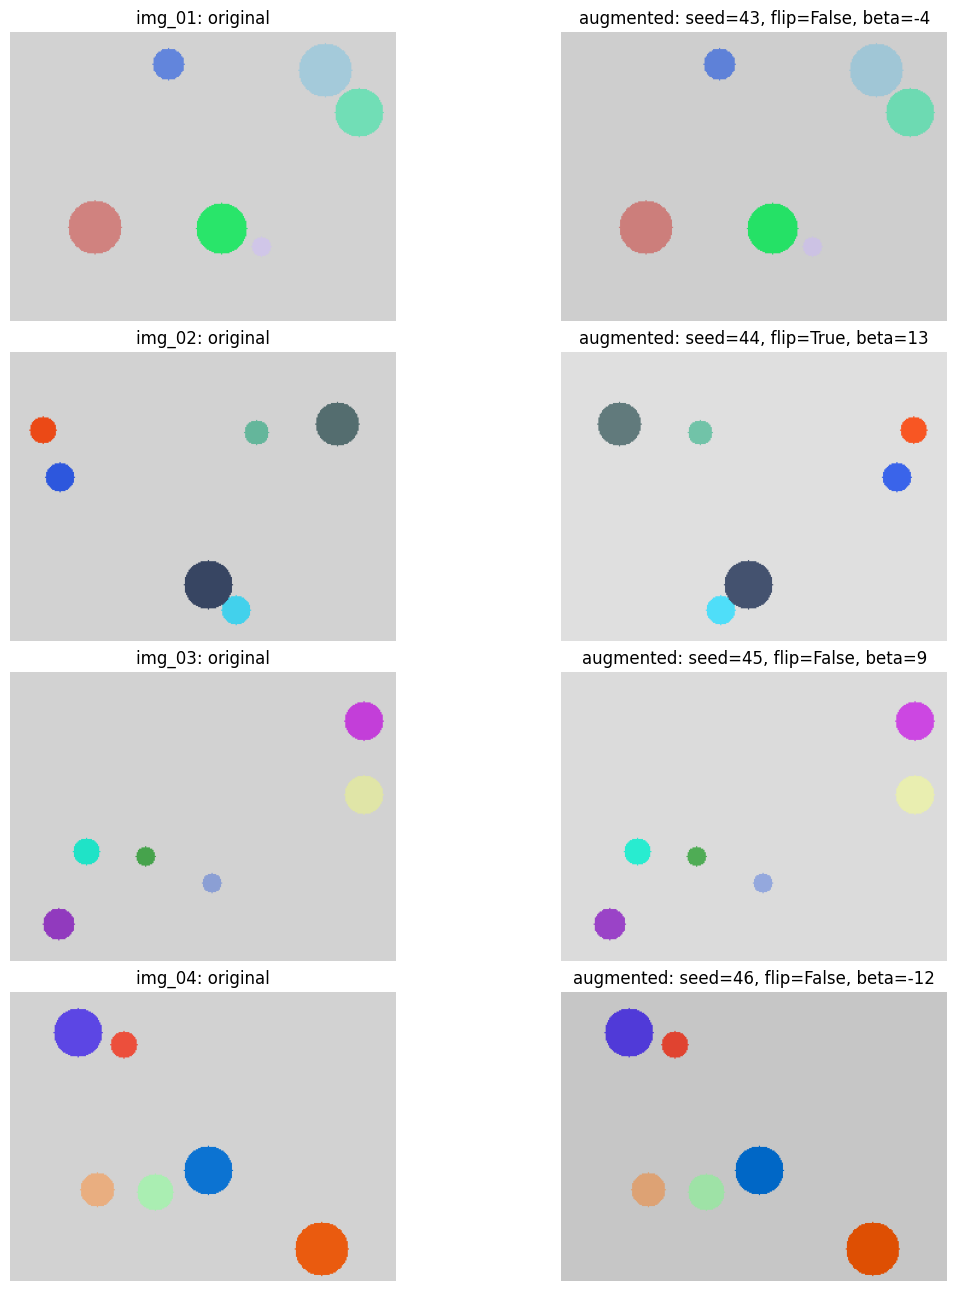

In [5]:
fig, axes = plt.subplots(len(recorded), 2, figsize=(11, 3.2 * len(recorded)), constrained_layout=True)
for index, item in enumerate(recorded.itertuples(index=False)):
    axes[index, 0].imshow(cv2.cvtColor(before_images[item.id], cv2.COLOR_BGR2RGB))
    axes[index, 0].set_title(f"{item.id}: original")
    axes[index, 1].imshow(cv2.cvtColor(processed_images[item.id], cv2.COLOR_BGR2RGB))
    axes[index, 1].set_title(f"augmented: seed={item.seed}, flip={item.flip}, beta={item.beta}")
    for ax in axes[index]: ax.axis("off")
plt.show()
os.chdir(notebook_start)

## 해석과 한계

- 원본 보존과 같은 seed의 재현은 표의 파일 해시·픽셀 비교로 확인합니다. 원본 SHA-256을 CSV에 적기만 하는 것과 실행 전후 보존을 확인하는 것은 다릅니다.
- 밝기 clip은 값의 범위를 지키지만, 포화된 영역에서는 밝기 차이와 세부 정보가 사라질 수 있습니다.
- 좌우반전은 방향·문자·좌우 구분이 라벨에 영향을 주는 문제에 부적절할 수 있습니다. 현재 manifest의 `allow_flip`은 모두 1이지만 코드가 해당 열을 검사하지는 않으므로 입력 정책이 바뀌면 이 점을 확인해야 합니다.
- 검증표는 증강 계산과 파일 기록의 일관성을 확인합니다. 이 증강으로 모델 성능이 개선됐거나 라벨 의미가 항상 보존된다는 검증은 아닙니다.